# Day 22
Warps Natural Earth country boundaries into the silhouette of a cat's face using cage-based deformation (mean value coordinates)

### Static Image

In [17]:
import json
import math
import os
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection, PolyCollection

In [59]:
# ----------------------------------------------------------------------
# CONFIG
# ----------------------------------------------------------------------
DATA_URL = ("https://raw.githubusercontent.com/nvkelso/natural-earth-vector/"
            "master/geojson/ne_110m_admin_0_countries.geojson")
DATA_CACHE = "countries.geojson"
SIMPLIFY_TOLERANCE = 0.12     # degrees; higher = coarser/faster
CAGE_RESOLUTION = 240         # points sampled around each outline
OUTPUT_FILE = "catesian_projection.png"

COLOR_BG = "#f4efe1"          # cream page background
COLOR_TITLE = "#1b4b44"       # deep teal
COLOR_SUBTITLE = "#3f6b63"
COLOR_BODY = "#e3a83e"        # mustard "ocean" / cat-face fill
COLOR_LAND = "#1f5c4e"        # deep teal land
COLOR_BORDER = "#f4efe1"      # country borders, same as bg (thin gaps)
COLOR_GRATICULE = "#c98b2e"   # graticule lines over the mustard fill
COLOR_OUTLINE = "#1b4b44"     # cat silhouette outline
COLOR_LABELED_LINE = "#8a3b1e"  # named lines (equator, meridian, tropics)

TITLE = "#30DayMapChallenge 2026"
SUBTITLE = "CATography"

SHOW_GRATICULE = True      # the regular thin lon/lat grid lines
SHOW_LABELED_LINES = True  # the named lines below (equator, tropics, etc.)

# (name, latitude-or-None, longitude-or-None, label position as a fraction
# 0-1 along the line, where to place the text). Exactly one of lat/lon
# should be set per entry.
LABELED_LINES = [ #Untype labels for them to disappear
    ("MEOWQUATO",         0.0,  None, 0.50), 
    ("PRIME MEOWRIDIAN",   None, 0.0,  0.28),
    ("TROPIC OF CATCER",   23.5, None, 0.80),
    ("TROPIC OF CAPRICAT", -23.5, None, 0.22),
]

In [23]:
# ----------------------------------------------------------------------
# 1. FETCH + SIMPLIFY COUNTRY BOUNDARIES
# ----------------------------------------------------------------------
def download_data():
    if not os.path.exists(DATA_CACHE):
        print("Downloading Natural Earth country boundaries...")
        urllib.request.urlretrieve(DATA_URL, DATA_CACHE)
    with open(DATA_CACHE, encoding="utf-8") as f:
        return json.load(f)


def rdp(points, epsilon):
    """Douglas-Peucker polyline simplification."""
    if len(points) < 3:
        return points

    def perp_dist(pt, a, b):
        (x, y), (x1, y1), (x2, y2) = pt, a, b
        dx, dy = x2 - x1, y2 - y1
        if dx == 0 and dy == 0:
            return math.hypot(x - x1, y - y1)
        t = ((x - x1) * dx + (y - y1) * dy) / (dx * dx + dy * dy)
        t = max(0, min(1, t))
        px, py = x1 + t * dx, y1 + t * dy
        return math.hypot(x - px, y - py)

    dmax, idx = 0, 0
    for i in range(1, len(points) - 1):
        d = perp_dist(points[i], points[0], points[-1])
        if d > dmax:
            idx, dmax = i, d
    if dmax > epsilon:
        left = rdp(points[:idx + 1], epsilon)
        right = rdp(points[idx:], epsilon)
        return left[:-1] + right
    return [points[0], points[-1]]


def split_antimeridian(ring):
    """Cut a ring into pieces wherever it jumps across the date line,
    so a single warped polygon never spans the whole map width."""
    pieces = [[]]
    for pt in ring:
        if pieces[-1] and abs(pt[0] - pieces[-1][-1][0]) > 180:
            pieces.append([])
        pieces[-1].append(pt)
    if len(pieces) > 1 and abs(pieces[0][0][0] - pieces[-1][-1][0]) <= 180:
        pieces[0] = pieces[-1] + pieces[0]
        pieces.pop()
    return pieces


def load_country_polygons():
    data = download_data()
    polys = []
    for feat in data["features"]:
        geom = feat.get("geometry")
        if geom is None:
            continue
        rings = ([geom["coordinates"][0]] if geom["type"] == "Polygon"
                  else [c[0] for c in geom["coordinates"]])
        for ring in rings:
            pts = [(round(x, 2), round(y, 2)) for x, y in ring]
            for piece in split_antimeridian(pts):
                simp = rdp(piece, SIMPLIFY_TOLERANCE)
                if len(simp) >= 3:
                    polys.append(simp)
    return polys

In [25]:
# ----------------------------------------------------------------------
# 2. CAT-FACE CAGE
# ----------------------------------------------------------------------
# Key silhouette points, clockwise in screen space (y-down), starting at
# the left ear tip. Tweak these to reshape the cat.
CAT_KEYPTS = [
    (275.8, 114.2), (216.8, 253.4), (175.5, 349.1), (122.4, 462.2), (116.5, 592.7), (193.2, 731.9),
    (334.8, 810.2), (500.0, 840.7), (665.2, 810.2), (806.8, 731.9), (883.5, 592.7), (877.6, 462.2),
    (824.5, 349.1), (783.2, 253.4), (724.2, 114.2), (606.2, 279.5), (500.0, 231.7), (393.8, 279.5),
]
# The two keypoints that sit on the shape's own left-right symmetry axis:
# the notch between the ears (top) and the bottom of the chin (bottom).
# Used below to line the map's poles up with them.
CAT_TOP_SYMMETRIC_POINT = (500.0, 231.7)     # the notch, CAT_KEYPTS[16]
CAT_BOTTOM_SYMMETRIC_POINT = (500.0, 840.7)  # the chin, CAT_KEYPTS[7]


def arc_length_resample(poly, n):
    """Resample a closed polyline into n points, evenly spaced by arc
    length (straight segments, no smoothing spline -- a cubic spline
    overshoots badly at the sharp ear-tip corners)."""
    poly = np.array(poly)
    d = np.sqrt(((poly - np.roll(poly, -1, axis=0)) ** 2).sum(axis=1))
    cum = np.concatenate([[0], np.cumsum(d)])
    total = cum[-1]
    targets = np.linspace(0, total, n, endpoint=False)
    out, j = [], 0
    for t in targets:
        while cum[j + 1] < t:
            j += 1
        seg_t = (t - cum[j]) / (cum[j + 1] - cum[j] + 1e-12)
        out.append(poly[j] + seg_t * (poly[(j + 1) % len(poly)] - poly[j]))
    return np.array(out)


def build_cat_cage(n):
    cage = arc_length_resample(CAT_KEYPTS, n)
    # Rotate the correspondence so the North Pole lands exactly at the
    # notch between the ears and the South Pole at the chin -- the two
    # points that sit on the cat's own left-right symmetry axis. This
    # keeps the prime meridian running straight down the middle and the
    # equator running level, instead of everything sitting on a diagonal.
    # See find_best_shift() below if you reshape the cat.
    shift = find_best_shift(cage, CAT_TOP_SYMMETRIC_POINT, CAT_BOTTOM_SYMMETRIC_POINT)
    return np.roll(cage, -shift, axis=0)


def find_best_shift(cage, top_point=None, bottom_point=None):
    """Find the rotation that lines the map's poles up with the cage.

    With top_point/bottom_point given (recommended -- e.g. the notch and
    chin keypoints), this places the North Pole at the cage point nearest
    top_point and the South Pole nearest bottom_point. For a left-right
    symmetric cat, passing the two points that sit ON that symmetry axis
    keeps the prime meridian vertical and the equator level.

    Without them, falls back to just maximizing (south_y - north_y),
    which finds *a* right-side-up rotation but, for anything other than
    a simple symmetric shape, can land on a diagonal/skewed alignment
    instead of the symmetric one -- always prefer passing the points
    when you know them.
    """
    n = len(cage)
    if top_point is not None and bottom_point is not None:
        top_idx = int(np.argmin(np.hypot(cage[:, 0] - top_point[0], cage[:, 1] - top_point[1])))
        return (top_idx - n // 4) % n
    scored = []
    for s in range(n):
        north_y = cage[(n // 4 + s) % n][1]
        south_y = cage[(3 * n // 4 + s) % n][1]
        scored.append((south_y - north_y, s))
    scored.sort(reverse=True)
    return scored[0][1]

In [27]:
# ----------------------------------------------------------------------
# 3. MOLLWEIDE SOURCE PROJECTION + MEAN VALUE COORDINATES WARP
# ----------------------------------------------------------------------
# Why Mollweide and not a plain lon/lat rectangle: on a rectangle, both
# poles are stretched into entire *edges* (every longitude at lat=90 maps
# to one edge). Cage-warping that means a pole's content gets smeared
# across a whole arc of the target outline -- this is exactly what made
# Antarctica look like a broken diagonal streak in earlier attempts.
# Mollweide maps each pole to a single POINT instead, so nothing gets
# smeared: Antarctica warps into a normal, compact, non-overlapping shape.
def mollweide(lon_deg, lat_deg):
    lon = math.radians(lon_deg)
    phi = math.radians(lat_deg)
    if abs(abs(phi) - math.pi / 2) < 1e-9:
        psi = math.copysign(math.pi, phi)
    else:
        psi = 2 * phi
        for _ in range(40):
            f = psi + math.sin(psi) - math.pi * math.sin(phi)
            fp = 1 + math.cos(psi)
            psi -= f / fp
    half = psi / 2
    x = (2 * math.sqrt(2) / math.pi) * lon * math.cos(half)
    y = math.sqrt(2) * math.sin(half)
    return x, y


# Mollweide's own outline is an ellipse with semi-axes (2*sqrt(2), sqrt(2)).
_ELLIPSE_A, _ELLIPSE_B = 2 * math.sqrt(2), math.sqrt(2)


def build_ellipse_cage(n):
    t = np.linspace(0, 2 * np.pi, n, endpoint=False)
    return np.stack([_ELLIPSE_A * np.cos(t), _ELLIPSE_B * np.sin(t)], axis=1)


def mvc_weights_batch(px, py, cage):
    """Mean value coordinates for many query points at once against one
    cage. Returns a (len(px), len(cage)) weight matrix."""
    cx, cy = cage[:, 0], cage[:, 1]
    sx = cx[None, :] - px[:, None]
    sy = cy[None, :] - py[:, None]
    r = np.maximum(np.hypot(sx, sy), 1e-10)
    sx1, sy1, r1 = np.roll(sx, -1, axis=1), np.roll(sy, -1, axis=1), np.roll(r, -1, axis=1)
    a = sx * sy1 - sy * sx1
    d = sx * sx1 + sy * sy1
    a = np.where(np.abs(a) < 1e-12, 1e-12, a)
    tanhalf = (r * r1 - d) / a
    w = (np.roll(tanhalf, 1, axis=1) + tanhalf) / r
    s = w.sum(axis=1, keepdims=True)
    s = np.where(np.abs(s) < 1e-12, 1e-12, s)
    return w / s


def make_warp_fn(src_cage, dst_cage):
    def warp_poly(pts):
        m = np.array([mollweide(lon, lat) for lon, lat in pts]) * 0.9999
        w = mvc_weights_batch(m[:, 0], m[:, 1], src_cage)
        return np.stack([w @ dst_cage[:, 0], w @ dst_cage[:, 1]], axis=1)
    return warp_poly

In [29]:
# ----------------------------------------------------------------------
# 4. GRATICULE
# ----------------------------------------------------------------------
def build_graticule():
    lines = []
    for lon in range(-180, 181, 15):
        lines.append([(lon, lat) for lat in np.arange(-89.9, 90, 2)])
    for lat in range(-75, 76, 15):
        lines.append([(lon, lat) for lon in np.arange(-179.9, 180, 2)])
    return lines


def label_angle_and_pos(warped_pts, frac):
    """Pick a point along a warped line and the local tangent angle there,
    so the label can be drawn rotated to follow the line's curve (like
    labels on a real atlas), right-side up rather than upside-down."""
    n = len(warped_pts)
    i = max(1, min(n - 2, int(frac * n)))
    (x0, y0), (x1, y1) = warped_pts[i - 1], warped_pts[i + 1]
    dx, dy = x1 - x0, y1 - y0
    angle = math.degrees(math.atan2(-dy, dx))  # -dy: the y-axis is flipped on screen
    if angle > 90 or angle < -90:
        angle += 180
    return warped_pts[i], angle

In [62]:
# ----------------------------------------------------------------------
# 5. MAIN
# ----------------------------------------------------------------------
def main():
    countries = load_country_polygons()

    cat_cage = build_cat_cage(CAGE_RESOLUTION)
    src_cage = build_ellipse_cage(CAGE_RESOLUTION)
    warp = make_warp_fn(src_cage, cat_cage)

    warped_countries = [warp(p) for p in countries]

    fig, ax = plt.subplots(figsize=(10, 8))
    fig.patch.set_facecolor(COLOR_BG)
    ax.set_facecolor(COLOR_BG)

    # cat-face / "ocean" fill, using the cage outline itself
    ax.fill(cat_cage[:, 0], cat_cage[:, 1], color=COLOR_BODY,
            edgecolor=COLOR_OUTLINE, linewidth=1.6, zorder=1)

    if SHOW_GRATICULE:
        graticule = build_graticule()
        warped_graticule = [warp(l) for l in graticule]
        ax.add_collection(LineCollection(warped_graticule, colors=COLOR_GRATICULE,
                                          linewidths=0.5, alpha=0.55, zorder=2))

    ax.add_collection(PolyCollection(warped_countries, facecolor=COLOR_LAND,
                                      edgecolor=COLOR_BORDER, linewidth=0.4,
                                      zorder=3))

    if SHOW_LABELED_LINES:
        for name, lat, lon, frac in LABELED_LINES:
            if lat is not None:
                pts = [(x, lat) for x in np.arange(-179.9, 180, 1)]
            else:
                pts = [(lon, y) for y in np.arange(-89.9, 90, 1)]
            warped_line = np.array(warp(pts))
            ax.plot(warped_line[:, 0], warped_line[:, 1], color=COLOR_LABELED_LINE,
                    linewidth=1.3, linestyle=(0, (6, 3)), alpha=0.85, zorder=4)
            (lx, ly), angle = label_angle_and_pos(warped_line, frac)
            ax.text(lx, ly, name, fontsize=9.5, color=COLOR_LABELED_LINE,
                    fontweight="bold", family="sans-serif", ha="center", va="center",
                    rotation=angle, rotation_mode="anchor", zorder=5,
                    bbox=dict(boxstyle="round,pad=0.15", facecolor=COLOR_BG,
                              edgecolor="none", alpha=0.75))

    ax.set_xlim(0, 1000)
    ax.set_ylim(1000, 0)
    ax.set_aspect("equal")
    ax.axis("off")

    fig.text(0.06, 0.94, TITLE, fontsize=22, fontweight="bold",
              color=COLOR_TITLE, family="sans-serif")
    fig.text(0.06, 0.905, SUBTITLE, fontsize=12,
              color=COLOR_SUBTITLE, family="sans-serif")

    plt.subplots_adjust(left=0.03, right=0.97, top=0.86, bottom=0.03)
    plt.savefig(OUTPUT_FILE, dpi=200, facecolor=COLOR_BG)
    print(f"Saved {OUTPUT_FILE}")

Saved catesian_projection.png


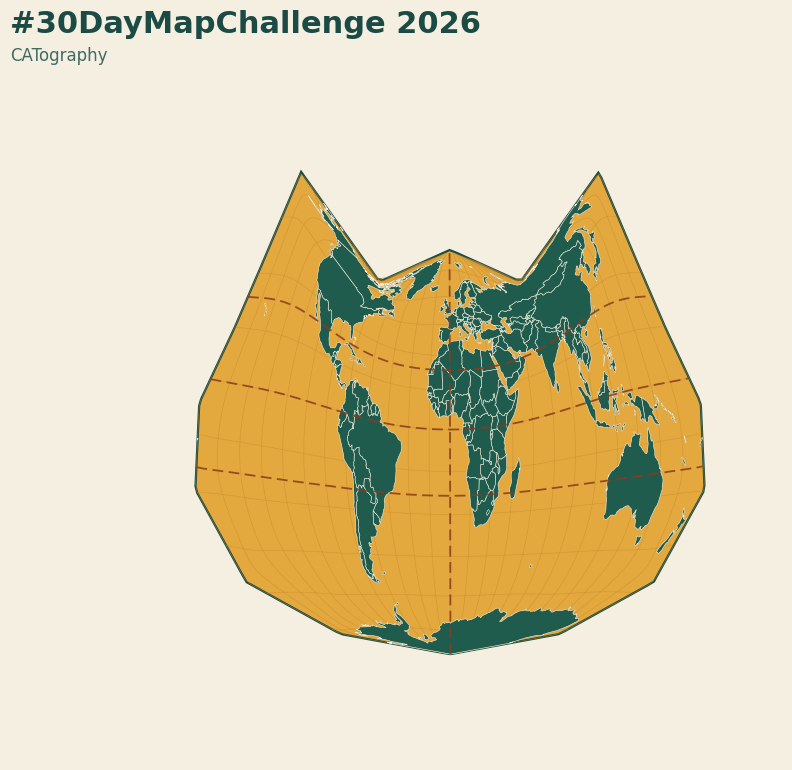

In [65]:
if __name__ == "__main__":
    main()

### Animation

In [45]:
import json
import math
import os
import shutil
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection, PolyCollection
from PIL import Image

In [47]:
# ----------------------------------------------------------------------
# CONFIG
# ----------------------------------------------------------------------
DATA_URL = ("https://raw.githubusercontent.com/nvkelso/natural-earth-vector/"
            "master/geojson/ne_110m_admin_0_countries.geojson")
DATA_CACHE = "countries.geojson"
SIMPLIFY_TOLERANCE = 0.15
CAGE_RESOLUTION = 240
FRAME_DIR = "_morph_frames"
OUTPUT_GIF = "catesian_morph.gif"

FRAMES_PER_LEG = 30     # frames spent morphing ellipse -> cat (and back)
HOLD_ON_MAP = 8         # frames paused on the plain map
HOLD_ON_CAT = 14        # frames paused on the finished cat
FRAME_MS = 45           # milliseconds per frame in the final gif
DPI = 100

COLOR_BG = "#f4efe1"
COLOR_TITLE = "#3f6b63"
COLOR_BODY = "#e3a83e"
COLOR_LAND = "#1f5c4e"
COLOR_BORDER = "#f4efe1"
COLOR_GRATICULE = "#c98b2e"
COLOR_OUTLINE = "#1b4b44"

In [49]:
# ----------------------------------------------------------------------
# 1. DATA
# ----------------------------------------------------------------------
def download_data():
    if not os.path.exists(DATA_CACHE):
        print("Downloading Natural Earth country boundaries...")
        urllib.request.urlretrieve(DATA_URL, DATA_CACHE)
    with open(DATA_CACHE, encoding="utf-8") as f:
        return json.load(f)


def rdp(points, epsilon):
    if len(points) < 3:
        return points

    def perp_dist(pt, a, b):
        (x, y), (x1, y1), (x2, y2) = pt, a, b
        dx, dy = x2 - x1, y2 - y1
        if dx == 0 and dy == 0:
            return math.hypot(x - x1, y - y1)
        t = ((x - x1) * dx + (y - y1) * dy) / (dx * dx + dy * dy)
        t = max(0, min(1, t))
        return math.hypot(x - (x1 + t * dx), y - (y1 + t * dy))

    dmax, idx = 0, 0
    for i in range(1, len(points) - 1):
        d = perp_dist(points[i], points[0], points[-1])
        if d > dmax:
            idx, dmax = i, d
    if dmax > epsilon:
        return rdp(points[:idx + 1], epsilon)[:-1] + rdp(points[idx:], epsilon)
    return [points[0], points[-1]]


def split_antimeridian(ring):
    pieces = [[]]
    for pt in ring:
        if pieces[-1] and abs(pt[0] - pieces[-1][-1][0]) > 180:
            pieces.append([])
        pieces[-1].append(pt)
    if len(pieces) > 1 and abs(pieces[0][0][0] - pieces[-1][-1][0]) <= 180:
        pieces[0] = pieces[-1] + pieces[0]
        pieces.pop()
    return pieces


def load_country_polygons():
    data = download_data()
    polys = []
    for feat in data["features"]:
        geom = feat.get("geometry")
        if geom is None:
            continue
        rings = ([geom["coordinates"][0]] if geom["type"] == "Polygon"
                  else [c[0] for c in geom["coordinates"]])
        for ring in rings:
            pts = [(round(x, 2), round(y, 2)) for x, y in ring]
            for piece in split_antimeridian(pts):
                simp = rdp(piece, SIMPLIFY_TOLERANCE)
                if len(simp) >= 3:
                    polys.append(simp)
    return polys


def build_graticule():
    lines = []
    for lon in range(-180, 181, 15):
        lines.append([(lon, lat) for lat in np.arange(-89.9, 90, 2)])
    for lat in range(-75, 76, 15):
        lines.append([(lon, lat) for lon in np.arange(-179.9, 180, 2)])
    return lines

In [51]:
# ----------------------------------------------------------------------
# 2. CAT-FACE CAGE
# ----------------------------------------------------------------------
CAT_KEYPTS = [
    (275.8, 114.2), (216.8, 253.4), (175.5, 349.1), (122.4, 462.2), (116.5, 592.7), (193.2, 731.9),
    (334.8, 810.2), (500.0, 840.7), (665.2, 810.2), (806.8, 731.9), (883.5, 592.7), (877.6, 462.2),
    (824.5, 349.1), (783.2, 253.4), (724.2, 114.2), (606.2, 279.5), (500.0, 231.7), (393.8, 279.5),
]
# Rotation so the North Pole lands exactly at the notch between the ears
# and the South Pole at the chin -- the two points on the cat's own
# left-right symmetry axis (CAT_KEYPTS[16] and CAT_KEYPTS[7]). Keeps the
# morph's prime meridian vertical instead of drifting diagonal. If you
# change CAT_KEYPTS, recompute this the same way catesian_projection.py's
# find_best_shift() does: find the cage index nearest the new notch point
# and set CAT_SHIFT = (that_index - CAGE_RESOLUTION // 4) % CAGE_RESOLUTION.
CAT_SHIFT = 151


def arc_length_resample(poly, n):
    poly = np.array(poly)
    d = np.sqrt(((poly - np.roll(poly, -1, axis=0)) ** 2).sum(axis=1))
    cum = np.concatenate([[0], np.cumsum(d)])
    total = cum[-1]
    targets = np.linspace(0, total, n, endpoint=False)
    out, j = [], 0
    for t in targets:
        while cum[j + 1] < t:
            j += 1
        st = (t - cum[j]) / (cum[j + 1] - cum[j] + 1e-12)
        out.append(poly[j] + st * (poly[(j + 1) % len(poly)] - poly[j]))
    return np.array(out)

In [53]:
# ----------------------------------------------------------------------
# 3. MOLLWEIDE SOURCE + MEAN VALUE COORDINATES
# ----------------------------------------------------------------------
def mollweide(lon_deg, lat_deg):
    lon = math.radians(lon_deg)
    phi = math.radians(lat_deg)
    if abs(abs(phi) - math.pi / 2) < 1e-9:
        psi = math.copysign(math.pi, phi)
    else:
        psi = 2 * phi
        for _ in range(40):
            f = psi + math.sin(psi) - math.pi * math.sin(phi)
            psi -= f / (1 + math.cos(psi))
    half = psi / 2
    x = (2 * math.sqrt(2) / math.pi) * lon * math.cos(half)
    y = math.sqrt(2) * math.sin(half)
    return x, y


ELLIPSE_A, ELLIPSE_B = 2 * math.sqrt(2), math.sqrt(2)


def ellipse_cage(n):
    t = np.linspace(0, 2 * np.pi, n, endpoint=False)
    return np.stack([ELLIPSE_A * np.cos(t), ELLIPSE_B * np.sin(t)], axis=1)


def mvc_weights_batch(px, py, cage):
    cx, cy = cage[:, 0], cage[:, 1]
    sx = cx[None, :] - px[:, None]
    sy = cy[None, :] - py[:, None]
    r = np.maximum(np.hypot(sx, sy), 1e-10)
    sx1, sy1, r1 = np.roll(sx, -1, axis=1), np.roll(sy, -1, axis=1), np.roll(r, -1, axis=1)
    a = sx * sy1 - sy * sx1
    d = sx * sx1 + sy * sy1
    a = np.where(np.abs(a) < 1e-12, 1e-12, a)
    tanhalf = (r * r1 - d) / a
    w = (np.roll(tanhalf, 1, axis=1) + tanhalf) / r
    s = w.sum(axis=1, keepdims=True)
    s = np.where(np.abs(s) < 1e-12, 1e-12, s)
    return w / s

In [55]:
# ----------------------------------------------------------------------
# 4. BUILD THE MORPH
# ----------------------------------------------------------------------
def ease(t):
    """Smoothstep easing so the morph accelerates then decelerates."""
    return t * t * (3 - 2 * t)


def main():
    countries = load_country_polygons()
    graticule = build_graticule()

    n = CAGE_RESOLUTION
    cat_cage = np.roll(arc_length_resample(CAT_KEYPTS, n), -CAT_SHIFT, axis=0)
    src_cage = ellipse_cage(n)

    # Flatten every coastline/graticule point into one big array so we
    # only compute the (expensive) weight matrix once.
    all_pts, seg_ranges, line_ranges = [], [], []
    for poly in countries:
        start = len(all_pts)
        all_pts.extend(poly)
        seg_ranges.append((start, len(all_pts)))
    for line in graticule:
        start = len(all_pts)
        all_pts.extend(line)
        line_ranges.append((start, len(all_pts)))

    all_pts = np.array(all_pts)
    moll = np.array([mollweide(lon, lat) for lon, lat in all_pts]) * 0.9999

    print(f"Computing weights for {len(all_pts)} points against a "
          f"{n}-point cage (this is the slow one-time step)...")
    W = mvc_weights_batch(moll[:, 0], moll[:, 1], src_cage)

    # The "plain map" starting cage: the same ellipse, scaled to fit the
    # canvas and centered on the cat's bounding box.
    cx0, cy0 = cat_cage[:, 0].mean(), cat_cage[:, 1].mean()
    scale = 900.0 / (2 * ELLIPSE_A)
    # NOTE: Mollweide's y is positive toward the North Pole (standard math
    # convention), but our canvas uses image coordinates where "up" is
    # smaller y. Without negating here, the starting ellipse frame would
    # have the South Pole on top -- an upside-down world map that then
    # visibly flips right-side-up mid-morph into the cat. Negating keeps
    # "north stays up" consistent across the whole animation.
    ellipse_canvas = np.stack([
        src_cage[:, 0] * scale + cx0,
        -src_cage[:, 1] * scale + cy0,
    ], axis=1)

    # ---- build the frame schedule: hold / morph / hold / morph back ----
    ts = [ease(i / (FRAMES_PER_LEG - 1)) for i in range(FRAMES_PER_LEG)]
    schedule = ([0.0] * HOLD_ON_MAP + ts
                + [1.0] * HOLD_ON_CAT + ts[::-1]
                + [0.0] * HOLD_ON_MAP)

    if os.path.exists(FRAME_DIR):
        shutil.rmtree(FRAME_DIR)
    os.makedirs(FRAME_DIR)

    print(f"Rendering {len(schedule)} frames...")
    frame_paths = []
    for i, t in enumerate(schedule):
        frame_cage = ellipse_canvas * (1 - t) + cat_cage * t
        pts = W @ frame_cage
        land_polys = [pts[s:e] for s, e in seg_ranges]
        grat_lines = [pts[s:e] for s, e in line_ranges]

        fig, ax = plt.subplots(figsize=(6, 6))
        fig.patch.set_facecolor(COLOR_BG)
        ax.set_facecolor(COLOR_BG)
        ax.fill(frame_cage[:, 0], frame_cage[:, 1], color=COLOR_BODY,
                edgecolor=COLOR_OUTLINE, linewidth=1.3, zorder=1)
        ax.add_collection(LineCollection(grat_lines, colors=COLOR_GRATICULE,
                                          linewidths=0.5, alpha=0.5, zorder=2))
        ax.add_collection(PolyCollection(land_polys, facecolor=COLOR_LAND,
                                          edgecolor=COLOR_BORDER, linewidth=0.3,
                                          zorder=3))
        ax.set_xlim(0, 1000)
        ax.set_ylim(1000, 0)
        ax.set_aspect("equal")
        ax.axis("off")
        fig.text(0.5, 0.05, "THE CATESIAN PROJECTION", fontsize=11,
                  color=COLOR_TITLE, family="sans-serif", ha="center",
                  fontweight="bold")
        plt.subplots_adjust(left=0.02, right=0.98, top=0.98, bottom=0.02)

        path = os.path.join(FRAME_DIR, f"f{i:03d}.png")
        plt.savefig(path, dpi=DPI, facecolor=fig.get_facecolor())
        plt.close(fig)
        frame_paths.append(path)
        if i % 10 == 0:
            print(f"  frame {i}/{len(schedule)}")

    print("Assembling gif...")
    images = [Image.open(p) for p in frame_paths]
    images[0].save(
        OUTPUT_GIF, save_all=True, append_images=images[1:],
        duration=FRAME_MS, loop=0, optimize=True,
    )
    shutil.rmtree(FRAME_DIR)
    print(f"Saved {OUTPUT_GIF}")

In [57]:
if __name__ == "__main__":
    main()

Computing weights for 11401 points against a 240-point cage (this is the slow one-time step)...
Rendering 90 frames...
  frame 0/90
  frame 10/90
  frame 20/90
  frame 30/90
  frame 40/90
  frame 50/90
  frame 60/90
  frame 70/90
  frame 80/90
Assembling gif...
Saved catesian_morph.gif
